#### Get particle information for ground truth annotation (json)

In [1]:
import numpy as np
import cv2
import pandas as pd
from utils import Utils
from cv2 import findContours
from skimage.measure import label, regionprops_table
from skimage.morphology import convex_hull_image
from typing import Tuple

INFO:albumentations.check_version:A new version of Albumentations is available: 2.0.8 (you have 1.4.13). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.


In [2]:
def is_overlapping_border(polygon, coords):

        
        """Check if any vertex of the polygon is outside the array boundaries."""
        
        # Extract window boundary
        y_start, y_end, x_start, x_end = coords[0], coords[1], coords[2], coords[3]
        
        for x, y in polygon:
            
            if x-10 <= x_start or x+10 <= x_start or x+10 >= x_end or x-10 >= x_end or y-10 <= y_start or y+10 <= y_start or y+10 >= y_end or y-10 >= y_end:

                return True  # Polygon overlaps with the border
            
        return False  # Polygon is inside the bounds

In [2]:
import numpy as np
from pycocotools.coco import COCO
import cv2
import os

# Paths to COCO JSON ground truth annotation
json_path = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\instances_val.json"

# Load COCO annotations
coco = COCO(json_path)

loading annotations into memory...
Done (t=0.14s)
creating index...
index created!


In [ ]:
# Path to the experimental images
exp_images_path = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\"

In [ ]:
dir_df = pd.DataFrame()
# Process each image in the dataset
for img_id in coco.imgs:
    # Get image metadata
    img_info = coco.loadImgs(img_id)[0]
    width, height = img_info['width'], img_info['height']
    file_name = img_info['file_name']

    print(f"Processing image: {file_name}")
    image, nm_to_px = Utils().read_image(exp_images_path + file_name)

    # Fetch all annotations for the current image
    ann_ids = coco.getAnnIds(imgIds=img_id)
    annotations = coco.loadAnns(ann_ids)

    # Initialize an empty mask (all background)
    combined_mask = np.zeros((height, width), dtype=np.uint8)

    # Empty list to add particle's properties
    all_masks = []
    all_masks_convex_hull = []

    # Accumulate all object masks
    for ann in annotations:
        mask = coco.annToMask(ann)  # Decode annotation to binary mask
        #combined_mask = np.maximum(combined_mask, mask)  # Logical OR

        # Find mask contour using skimage find_contours
        contours, _  = Utils().get_mask_contours(mask)

        # Make sure the contours list is not empty              
        if contours != []:

            # If more than one contour found in mask, get the longest
            list_len = [len(i) for i in contours]
            longest_index = np.argmax(np.array(list_len))
            # Sometimes two polygons are found in the same detection, we want to take the last - which is the biggest
            paired_list = list(zip(contours[longest_index][::2], contours[longest_index][1::2]))
            # Convert tuples to lists (optional)
            contours = [list(pair) for pair in paired_list]

            # Boundaries of the image (y_start, y_end, x_start, x_end)
            coords = (0, image.shape[1], 0, image.shape[0])

            # Extract masked pixels from original image
            # masked_pixels = image[mask]
            # # Remove region containing white pixels - its the ruler
            # is_white = np.any(np.all(masked_pixels == 255, axis=1))
            # # Remove region containing black pixels - its the ruler
            # is_black = np.any(np.all(masked_pixels == 0, axis=1))

            # Remove detections in the boundaries do we don't have "half particles"
            if not is_overlapping_border(contours, coords):
                
                # Create an empty canvas to plot the contours. This will assure that the calculations are doing done 
                # with the same polygon drawn
                mask = np.zeros_like(image) 

                all_masks, all_masks_convex_hull = Utils().get_particle_properties(mask, contours, all_masks, all_masks_convex_hull, nm_to_px)
                # Draw the contours on the mask
                # if self.checkBoxShowInstances.isChecked():
                
                points = np.array(contours)

                x = points[:, 0]  # Extract x-coordinates
                y = points[:, 1]  # Extract y-coordinates
                draw_polygon = np.column_stack((x, y)).astype(np.int32)   
                # Draw the bumpy circle contour
                img = cv2.polylines(image, [draw_polygon], isClosed=True, color=(0, 0, 255), thickness=5)
            
            
    # All detection can be removed by the border filter, so we need to check again if the list is empty 
    if all_masks != []: 

        cv2.imwrite(exp_images_path + "gt_"+ file_name, img) # save image

        final_df = Utils().get_particle_properties_final_df(all_masks, all_masks_convex_hull)

    # Create an zeros entry if no particles were detected
    else: 

        final_df = pd.DataFrame(columns=['contours','axis_major_length', 'axis_minor_length', 'eccentricity', 'area', 'aspect ratio', 'circularity', 'solidity', 'convexity'])

    final_df['FileName'] = file_name

    final_df['OriginalPath'] = file_name

    final_df['nm2pixels'] = nm_to_px

    final_df['PredictionModel'] = 'manual'
    
    dir_df = pd.concat([dir_df, final_df])   

dir_df.to_csv(exp_images_path + 'stats.csv')

Processing image: 0.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 1.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 2.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 3.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 4.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 5.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 6.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 7.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 8.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 9.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 10.png
0
255

C:\Users\Natalia\AppData\Local\Temp\ipykernel_15452\1483197814.py:92: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  dir_df = pd.concat([dir_df, final_df])


Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 12.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 13.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 14.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 15.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 16.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 17.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 18.png
0
255


C:\Users\Natalia\AppData\Local\Temp\ipykernel_15452\1483197814.py:92: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  dir_df = pd.concat([dir_df, final_df])


Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 19.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 20.png
0
255


...

Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 227.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 228.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 229.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 230.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 231.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 232.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 233.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 234.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 235.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 236.png
0
255
Invalid fo

C:\Users\Natalia\AppData\Local\Temp\ipykernel_15452\1483197814.py:92: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  dir_df = pd.concat([dir_df, final_df])


Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 246.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 247.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 248.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 249.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 250.png
0
255


C:\Users\Natalia\AppData\Local\Temp\ipykernel_15452\1483197814.py:92: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  dir_df = pd.concat([dir_df, final_df])


Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 251.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 252.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 253.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 254.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
Processing image: 255.png
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm


In [103]:
# df_manual = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMapp\\experimental_1024\\images\\stats.csv")
# df_pred = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMapp\\experimental_1024\\images\\segmentations\\20250512151710model_final_polymer+silica_new3\\stats.csv")

# df_manual = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\annotated\\stats.csv")
# df_pred = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\annotated\\segmentations\\20250514160139model_final_glasgow3_2048_run1\\stats.csv")

# df_manual = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\stats.csv")
# df_pred = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\segmentations\\20250515221711_20250510201454mary-scott-training4_histogrameq_0.9_coco\\stats.csv")

df_manual = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\stats.csv")
df_pred = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-png\\segmentations\\20250426100022\\postprocessed_stats.csv")

In [97]:
compare_px_pred = df_pred.groupby('FileName').agg(total_annotated=('nm2pixels', 'mean'))
compare_px_manual = df_manual.groupby('FileName').agg(total_annotated=('nm2pixels', 'mean'))
pd.concat([compare_px_pred, compare_px_manual], axis=1)

,total_annotated,total_annotated
FileName,,
Co0_2_TEM_images_0.png,1.0,NaN
Co0_2_TEM_images_1.png,1.0,NaN
Co0_2_TEM_images_2.png,1.0,NaN
Co0_2_TEM_images_3.png,1.0,NaN
Co0_2_TEM_images_4.png,1.0,NaN
...,...,...
95.png,NaN,1.0
96.png,NaN,1.0
97.png,NaN,1.0


In [ ]:
# # Get nm to pixel value from .dm4
# import os
# dm4_dir = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\PAT4NANO_data\\"

# # Go through each sub folder in the main directory
# file_names =[]
# nm2pix =[]
# for dir, subdir, files in os.walk(dm4_dir):
#     #print("Processing directory:", dir)
#     for dir_name in subdir:
#         #print("Subdirectory:", dir_name)
#         # Check if the subdirectory contains .dm4 files
#         #if any(f.endswith('.dm4') for f in os.listdir(os.path.join(dir, dir_name))):
#         dm4_files = [f for f in os.listdir(os.path.join(dir, dir_name)) if f.endswith('.dm4')]
#         for dm4_file in dm4_files:
#             #dm4_dir = os.path.join(subdir, dir_name)
#             image, nm_to_px = Utils().read_image(os.path.join(dir, dir_name,dm4_file))
#             #print(f"Processing .dm4 file: {dm4_file} with nm to pixel value: {nm_to_px}")
#             file_names.append(dir_name + '_' + dm4_file)
#             nm2pix.append(nm_to_px)
# nm2pix_df = pd.DataFrame({'FileName': file_names, 'nm2pixels': nm2pix})
# nm2pix_df.to_csv(dm4_dir + 'polymer_silica_nm2pixels.csv', index=False)

In [61]:
nm2pix_df = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\PAT4NANO_data\\polymer_silica_nm2pixels.csv")
nm2pix_df

,FileName,nm2pixels
0,2021-02-04_silicaSpheres_200nm_A5_2021-02-04_S...,0.231631
1,2021-02-04_silicaSpheres_200nm_A5_2021-02-04_S...,0.700280
2,2021-02-04_silicaSpheres_200nm_A5_2021-02-04_S...,0.700280
3,2021-02-04_silicaSpheres_200nm_A5_2021-02-04_S...,0.700280
4,2021-02-04_silicaSpheres_200nm_A5_2021-02-04_S...,0.700280
...,...,...
87,2021-02-05_PolymerSpheres_A1_2021-02-05_Polyme...,1.831501
88,2021-02-05_PolymerSpheres_A1_2021-02-05_Polyme...,0.137363
89,2021-02-05_PolymerSpheres_A1_2021-02-05_Polyme...,0.915750
90,2021-02-05_PolymerSpheres_A1_2021-02-05_Polyme...,0.177763


In [62]:
df_manual['FileName'] = df_manual['FileName'].str[:-4]
df_pred['FileName'] = df_pred['FileName'].str[:-4]
nm2pix_df['FileName'] = nm2pix_df['FileName'].str[:-4]

In [63]:
df_manual['nm2pixels'] = df_manual['FileName'].map(nm2pix_df.set_index('FileName')['nm2pixels'])
df_pred['nm2pixels'] = df_pred['FileName'].map(nm2pix_df.set_index('FileName')['nm2pixels'])

In [104]:
# Convert to pixels for polymer data

# df_manual['axis_major_length'] = df_manual['axis_major_length']/ df_manual['nm2pixels']
# df_manual['axis_minor_length'] = df_manual['axis_minor_length']/ df_manual['nm2pixels']
# df_manual['area'] = df_manual['area']/ (df_manual['nm2pixels'] ** 2)

# df_pred['axis_major_length'] = df_pred['axis_major_length']/ df_pred['nm2pixels']
# df_pred['axis_minor_length'] = df_pred['axis_minor_length']/ df_pred['nm2pixels']
# df_pred['area'] = df_pred['area']/ (df_pred['nm2pixels'] ** 2)  

# Convert to pixels for mary scott data

df_manual['axis_major_length'] = df_manual['axis_major_length']/ 86
df_manual['axis_minor_length'] = df_manual['axis_minor_length']/ 86
df_manual['area'] = df_manual['area']/ (86 ** 2)

df_pred['axis_major_length'] = df_pred['axis_major_length']/ 86
df_pred['axis_minor_length'] = df_pred['axis_minor_length']/ 86
df_pred['area'] = df_pred['area']/ (86 ** 2)  

In [105]:
df_histogram = pd.concat([df_manual['axis_major_length'], df_pred['axis_major_length']], axis=1, keys=['df_manual', 'df_pred'])

In [106]:
df_histogram

,df_manual,df_pred
0,1.077660,0.881655
1,1.065372,0.998285
2,1.041198,1.074228
3,1.165660,0.941544
4,1.027156,1.071338
...,...,...
39584,NaN,1.141051
39585,NaN,1.287765
39586,NaN,1.118135
39587,NaN,1.245434


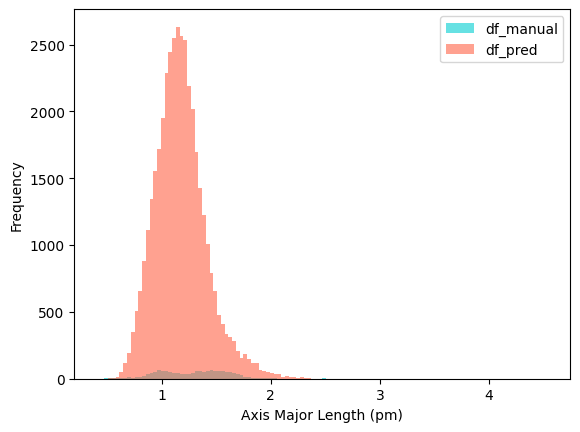

In [107]:
import matplotlib.pyplot as plt
colours = ['darkturquoise', 'tomato']
ax = df_histogram.plot.hist(bins=120, alpha=0.6, color=colours)
ax.set_xlabel("Axis Major Length (pm)")
plt.savefig('C:\\Users\\Natalia\\OneDrive\\Documents\\Thesis\\histogram_size_cobalt_B_processed.png', dpi=300, bbox_inches='tight')



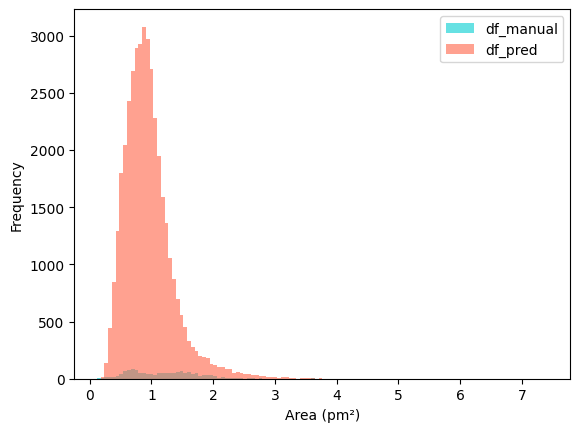

In [108]:
df_histogram_area = pd.concat([df_manual['area'], df_pred['area']], axis=1, keys=['df_manual', 'df_pred'])
colours = ['darkturquoise', 'tomato']
ax = df_histogram_area.plot.hist(bins=120, alpha=0.6, color=colours)
ax.set_xlabel("Area (pm²)")
plt.savefig('C:\\Users\\Natalia\\OneDrive\\Documents\\Thesis\\histogram_area_cobalt_B_processed.png', dpi=300, bbox_inches='tight')



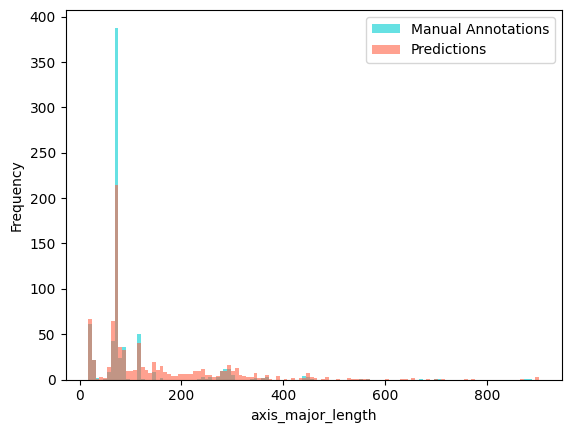

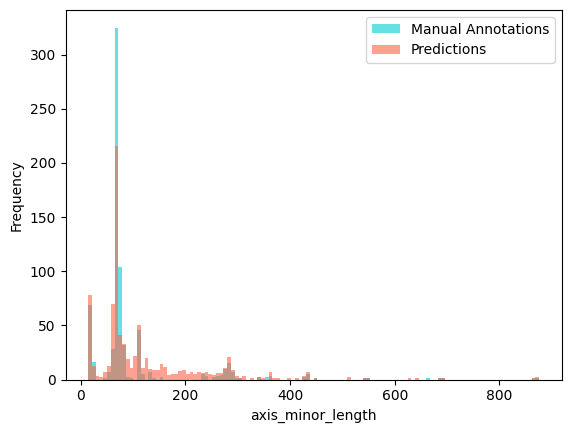

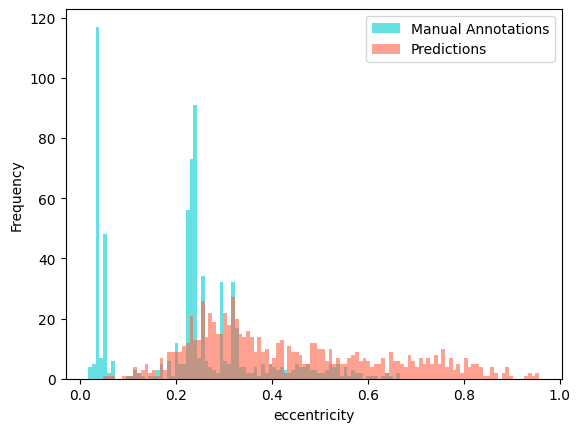

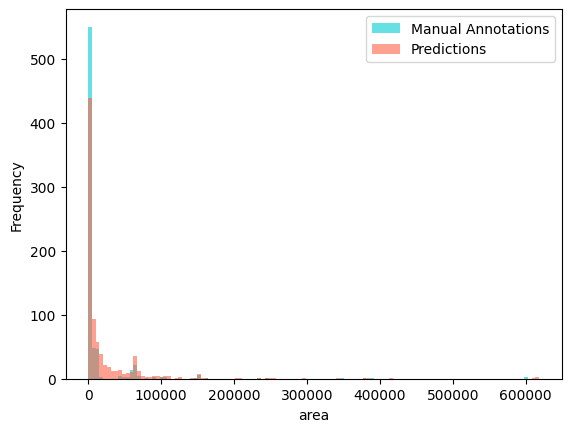

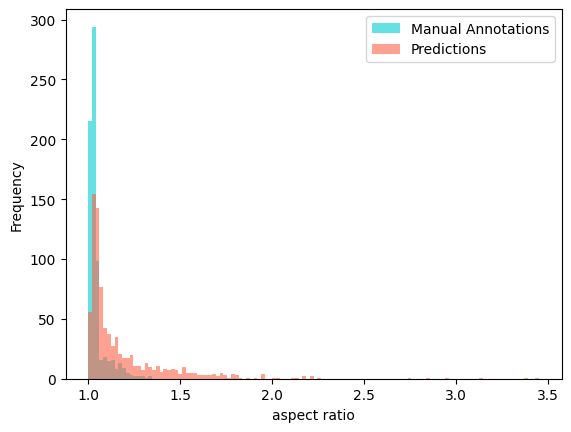

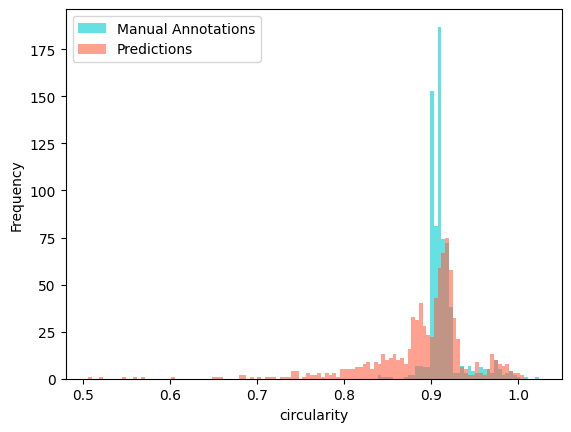

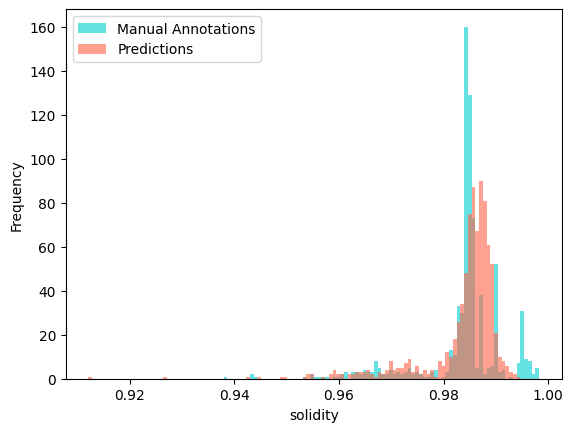

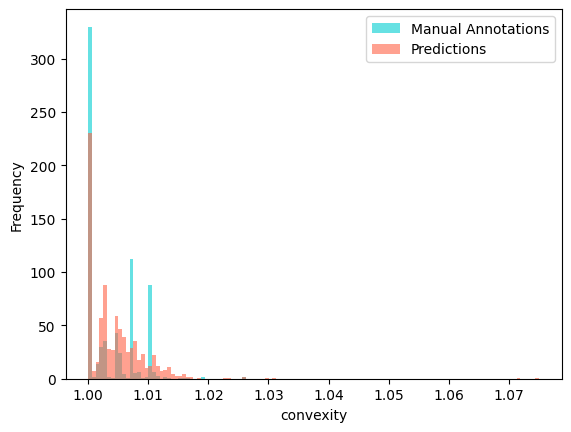

In [11]:
for i in df_pred.columns[2:10]:
    df_histogram = pd.concat([df_manual[i], df_pred[i]], axis=1, keys=['Manual Annotations', 'Predictions'])
    colours = ['darkturquoise', 'tomato']
    ax = df_histogram.plot.hist(bins=120, alpha=0.6, color=colours)
    ax.set_xlabel(i)
    plt.savefig(f'C:\\Users\\Natalia\\OneDrive\\Documents\\Thesis\\histogram_{i}_polymer_A.png', dpi=300, bbox_inches='tight')
    